In [26]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

In [27]:
data=pd.read_csv('Dataset/household_power_consumption.txt',sep=";",na_values=['?'],low_memory=False)

In [28]:
print(data.head())
print("\nShape:", data.shape)
print("\nColumns:", data.columns.tolist())
print("\nData types:")
print(data.dtypes)

         Date      Time  Global_active_power  Global_reactive_power  Voltage  \
0  16/12/2006  17:24:00                4.216                  0.418   234.84   
1  16/12/2006  17:25:00                5.360                  0.436   233.63   
2  16/12/2006  17:26:00                5.374                  0.498   233.29   
3  16/12/2006  17:27:00                5.388                  0.502   233.74   
4  16/12/2006  17:28:00                3.666                  0.528   235.68   

   Global_intensity  Sub_metering_1  Sub_metering_2  Sub_metering_3  
0              18.4             0.0             1.0            17.0  
1              23.0             0.0             1.0            16.0  
2              23.0             0.0             2.0            17.0  
3              23.0             0.0             1.0            17.0  
4              15.8             0.0             1.0            17.0  

Shape: (2075259, 9)

Columns: ['Date', 'Time', 'Global_active_power', 'Global_reactive_power', 'Vo

In [29]:

print("Missing values:")
print(data.isnull().sum())

print("\nMissing percentage:")
print(data.isnull().mean() * 100)

print("\nStatistical summary:")
print(data.describe())


Missing values:
Date                         0
Time                         0
Global_active_power      25979
Global_reactive_power    25979
Voltage                  25979
Global_intensity         25979
Sub_metering_1           25979
Sub_metering_2           25979
Sub_metering_3           25979
dtype: int64

Missing percentage:
Date                     0.000000
Time                     0.000000
Global_active_power      1.251844
Global_reactive_power    1.251844
Voltage                  1.251844
Global_intensity         1.251844
Sub_metering_1           1.251844
Sub_metering_2           1.251844
Sub_metering_3           1.251844
dtype: float64

Statistical summary:
       Global_active_power  Global_reactive_power       Voltage  \
count         2.049280e+06           2.049280e+06  2.049280e+06   
mean          1.091615e+00           1.237145e-01  2.408399e+02   
std           1.057294e+00           1.127220e-01  3.239987e+00   
min           7.600000e-02           0.000000e+00  2.232000e

In [30]:
data['datetime']=pd.to_datetime(data["Date"] + " " + data['Time'],
    dayfirst=True,
    errors='coerce')
data=data.drop(columns=['Date','Time'])
data=data.dropna(subset=['datetime'])
data=data.set_index('datetime').sort_index()
data.head()
print(data.index.min(), data.index.max())

2006-12-16 17:24:00 2010-11-26 21:02:00


In [35]:
data.isnull().sum()

Global_active_power      25979
Global_reactive_power    25979
Voltage                  25979
Global_intensity         25979
Sub_metering_1           25979
Sub_metering_2           25979
Sub_metering_3           25979
dtype: int64

In [34]:
data.tail()

,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
datetime,,,,,,,
2010-11-26 20:58:00,0.946,0.0,240.43,4.0,0.0,0.0,0.0
2010-11-26 20:59:00,0.944,0.0,240.00,4.0,0.0,0.0,0.0
2010-11-26 21:00:00,0.938,0.0,239.82,3.8,0.0,0.0,0.0
2010-11-26 21:01:00,0.934,0.0,239.70,3.8,0.0,0.0,0.0
2010-11-26 21:02:00,0.932,0.0,239.55,3.8,0.0,0.0,0.0


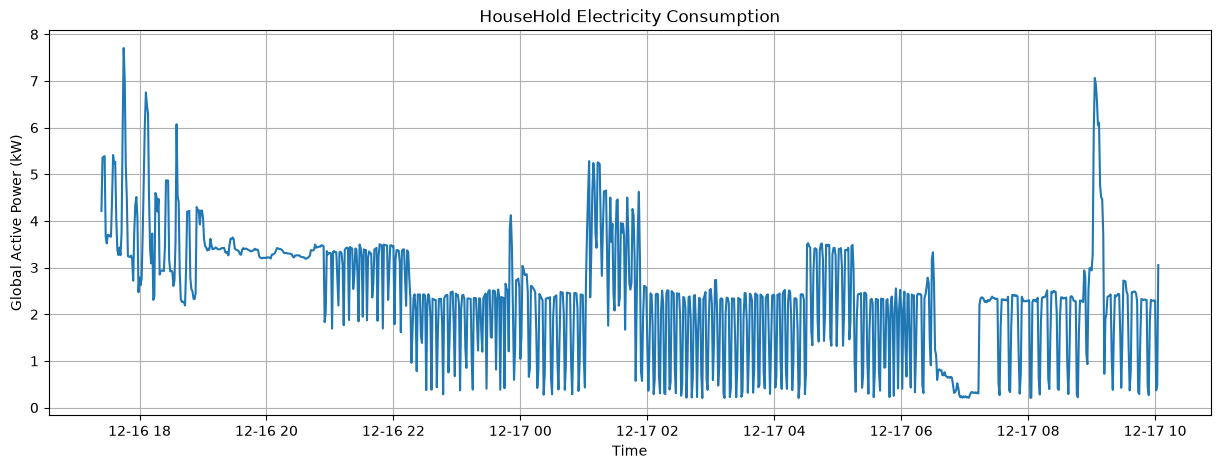

In [38]:
plt.figure(figsize=(15,5))
plt.plot(data.index[:1000],data['Global_active_power'].iloc[:1000])
plt.title("HouseHold Electricity Consumption")
plt.xlabel("Time")
plt.ylabel("Global Active Power (kW)")
plt.grid(True)
plt.show()

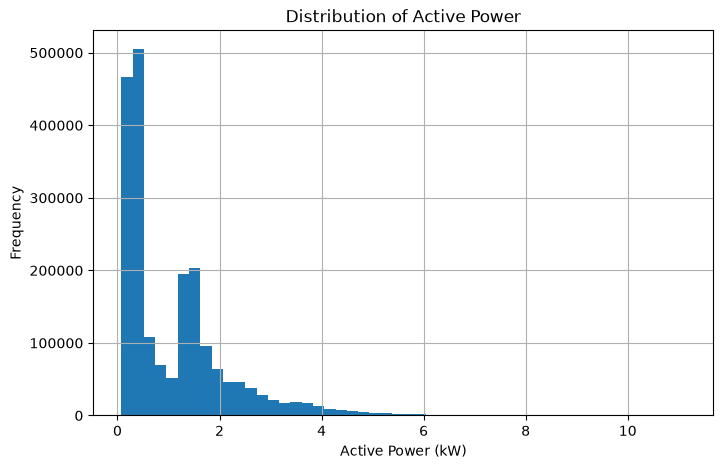

In [39]:
plt.figure(figsize=(8,5))
data['Global_active_power'].hist(bins=50)
plt.title("Distribution of Active Power")
plt.xlabel("Active Power (kW)")
plt.ylabel("Frequency")
plt.show()

In [41]:
power_cols = [
    "Global_active_power",
    "Global_reactive_power",
    "Voltage",
    "Global_intensity"
]
submeter_cols = [
    "Sub_metering_1",
    "Sub_metering_2",
    "Sub_metering_3"
]

hourly_power = data[power_cols].resample("h").mean()
hourly_submeter = data[submeter_cols].resample("h").sum(
    min_count=1
)
hourly_df = pd.concat(
    [hourly_power, hourly_submeter],
    axis=1
)
hourly_df.head()

,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
datetime,,,,,,,
2006-12-16 17:00:00,4.222889,0.229000,234.643889,18.100000,0.0,19.0,607.0
2006-12-16 18:00:00,3.632200,0.080033,234.580167,15.600000,0.0,403.0,1012.0
2006-12-16 19:00:00,3.400233,0.085233,233.232500,14.503333,0.0,86.0,1001.0
2006-12-16 20:00:00,3.268567,0.075100,234.071500,13.916667,0.0,0.0,1007.0
2006-12-16 21:00:00,3.056467,0.076667,237.158667,13.046667,0.0,25.0,1033.0


In [42]:
print("Hourly shape:", hourly_df.shape)

Hourly shape: (34589, 7)


In [43]:

hourly_df = hourly_df.interpolate(
    method="time",
    limit=3,
    limit_area="inside"
)
hourly_df = hourly_df.dropna()
print("Remaining missing values:")
print(hourly_df.isnull().sum())
print("Final shape:", hourly_df.shape)


Remaining missing values:
Global_active_power      0
Global_reactive_power    0
Voltage                  0
Global_intensity         0
Sub_metering_1           0
Sub_metering_2           0
Sub_metering_3           0
dtype: int64
Final shape: (34190, 7)


In [45]:
hourly_df["hour"] = hourly_df.index.hour
hourly_df["day_of_week"] = hourly_df.index.dayofweek
hourly_df["is_weekend"] = (
    hourly_df["day_of_week"] >= 5
).astype(int)
hourly_df["hour_sin"] = np.sin(
    2 * np.pi * hourly_df["hour"] / 24
)
hourly_df["hour_cos"] = np.cos(
    2 * np.pi * hourly_df["hour"] / 24
)
hourly_df["day_sin"] = np.sin(
    2 * np.pi * hourly_df["day_of_week"] / 7
)
hourly_df["day_cos"] = np.cos(
    2 * np.pi * hourly_df["day_of_week"] / 7
)
hourly_df = hourly_df.drop(
    columns=["hour", "day_of_week"]
)
hourly_df.head()

,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3,is_weekend,hour_sin,hour_cos,day_sin,day_cos
datetime,,,,,,,,,,,,
2006-12-16 17:00:00,4.222889,0.229000,234.643889,18.100000,0.0,19.0,607.0,1,-0.965926,-2.588190e-01,-0.974928,-0.222521
2006-12-16 18:00:00,3.632200,0.080033,234.580167,15.600000,0.0,403.0,1012.0,1,-1.000000,-1.836970e-16,-0.974928,-0.222521
2006-12-16 19:00:00,3.400233,0.085233,233.232500,14.503333,0.0,86.0,1001.0,1,-0.965926,2.588190e-01,-0.974928,-0.222521
2006-12-16 20:00:00,3.268567,0.075100,234.071500,13.916667,0.0,0.0,1007.0,1,-0.866025,5.000000e-01,-0.974928,-0.222521
2006-12-16 21:00:00,3.056467,0.076667,237.158667,13.046667,0.0,25.0,1033.0,1,-0.707107,7.071068e-01,-0.974928,-0.222521


In [47]:
len(hourly_df.columns)

12

In [48]:

hourly_df.to_csv("hourly_data.csv", index=False)


